# RQ1 reproduces the paper experiment grid with recurring dynamic fault windows.

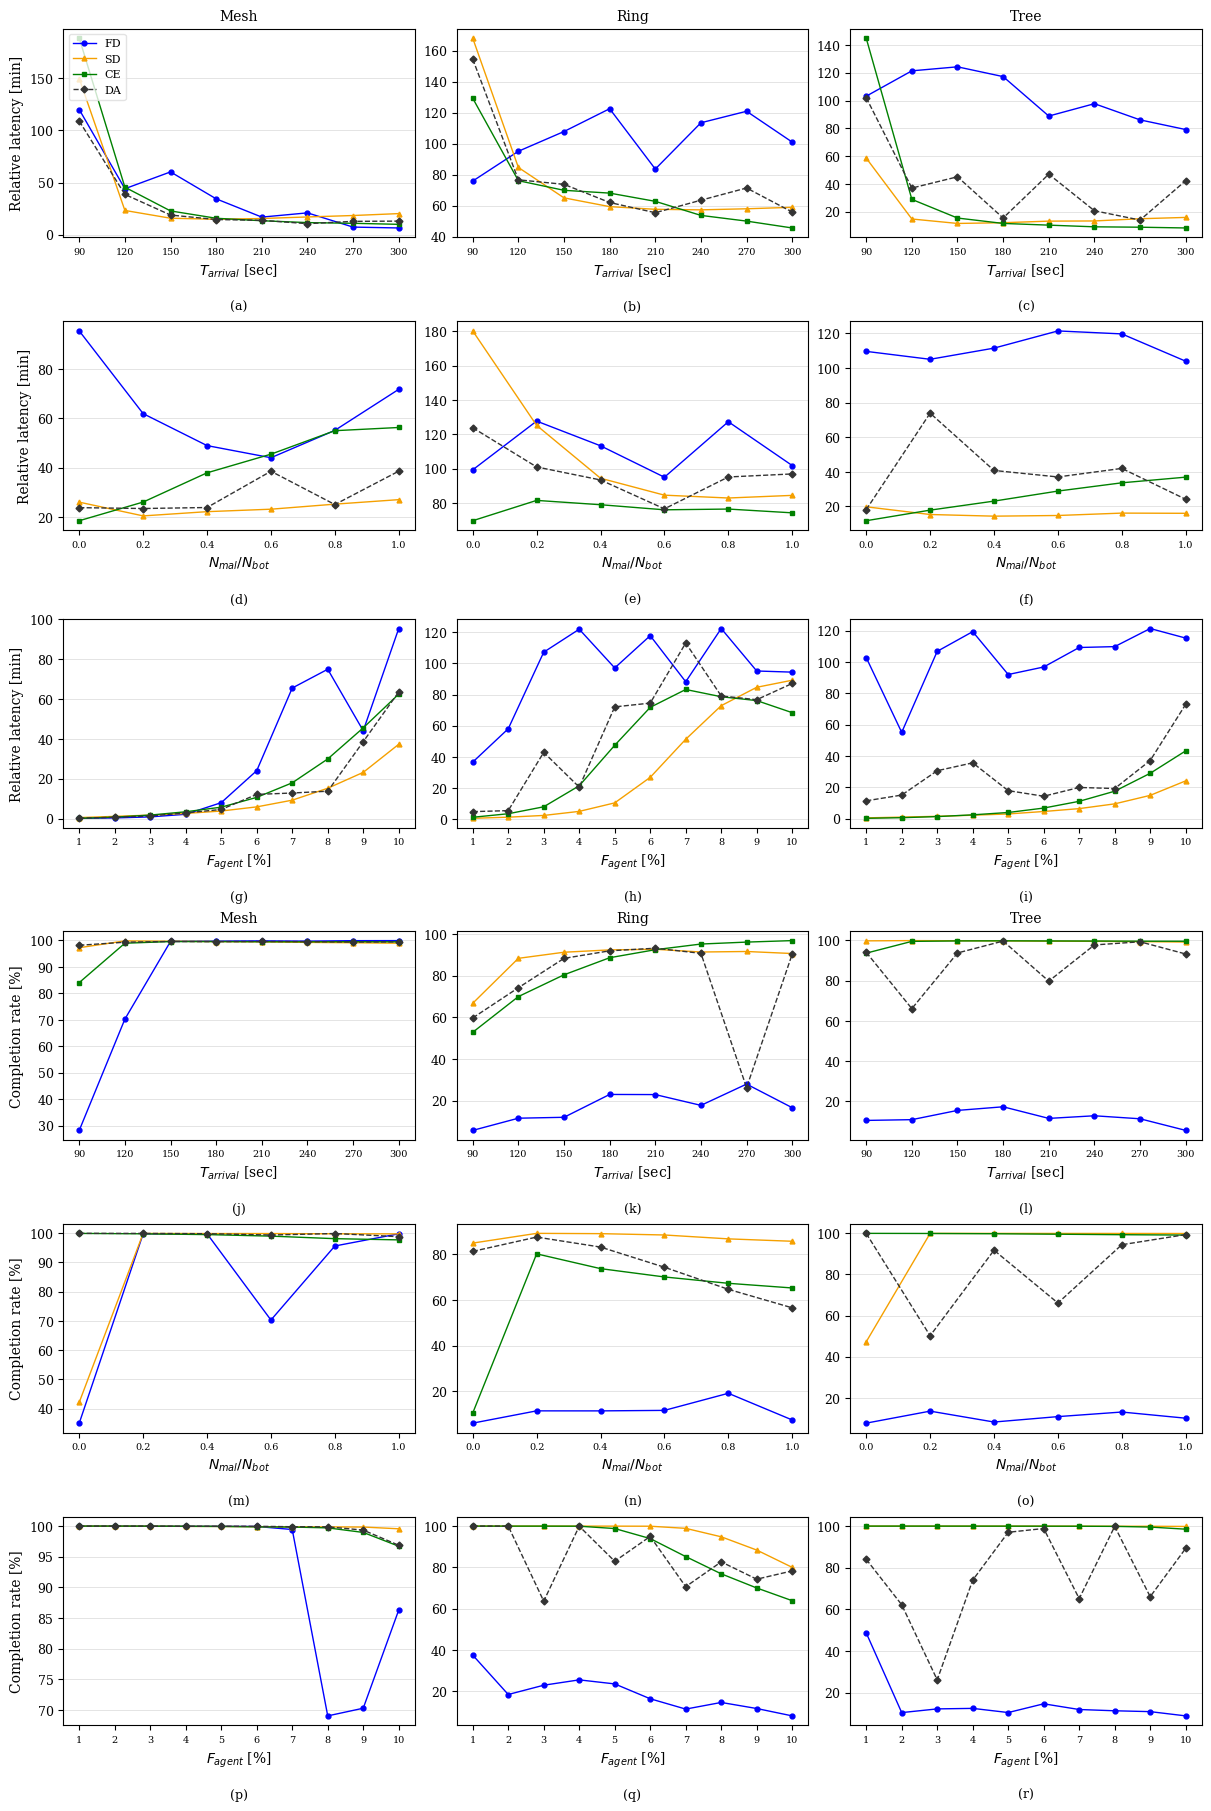

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for candidate in (Path.cwd() / 'Paper Results', Path.cwd()):
    if (candidate / 'RQ1' / 'runs.csv').exists():
        ROOT = candidate
        break
else:
    ROOT = Path.cwd() / 'Paper Results'

RUNS_PATH = ROOT / 'RQ1' / 'runs.csv'
FIGURES_DIR = ROOT / 'paper_figures_latest'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROFILE = 'table-aligned-rq1-v1'
METRIC_VERSION = 'relative-latency-v1'
FD_POLICY_VERSION = 'limited-patrol-v2'

TOPOLOGIES = [('mesh25', 'Mesh'), ('ring25', 'Ring'), ('tree25', 'Tree')]
SWEEPS = (
    ('workload', 'item_spawning_time', [90, 120, 150, 180, 210, 240, 270, 300], r'$T_{arrival}$ [sec]'),
    ('security', 'malicious_ratio', [value / 100 for value in (0, 20, 40, 60, 80, 100)], r'$N_{mal}/N_{bot}$'),
    ('reliability', 'fail_prob_pct', list(range(1, 11)), r'$F_{agent}$ [%]'),
)

STYLE = {
    'FD': {'color': '#0000ff', 'marker': 'o', 'linestyle': '-'},
    'SD': {'color': '#f5a000', 'marker': '^', 'linestyle': '-'},
    'CE': {'color': '#008000', 'marker': 's', 'linestyle': '-'},
    'DA': {'color': '#333333', 'marker': 'D', 'linestyle': '--'},
}
ORDER = ('FD', 'SD', 'CE', 'DA')

runs = pd.read_csv(RUNS_PATH)
runs = runs[(runs['status'].astype(str) == 'ok') & (runs['experiment_profile'].astype(str) == PROFILE)].copy()
if 'analysis_metric_version' not in runs.columns:
    raise RuntimeError('RQ1 runs.csv predates the relative-latency analysis. Re-run the current RQ1 campaign.')
runs = runs[runs['analysis_metric_version'].astype(str) == METRIC_VERSION].copy()
if 'fd_policy_version' not in runs.columns:
    raise RuntimeError('RQ1 runs.csv predates the limited-patrol FD policy. Re-run the current RQ1 campaign.')
runs = runs[runs['fd_policy_version'].astype(str) == FD_POLICY_VERSION].copy()
if runs.empty:
    raise RuntimeError('No RQ1 runs for the table-aligned campaign are available yet.')
for column in ('item_spawning_time', 'malicious_ratio', 'fail_prob', 'avg_relative_latency_s', 'completion_rate'):
    runs[column] = pd.to_numeric(runs[column], errors='coerce')
runs['malicious_ratio'] = runs['malicious_ratio'].round(6)
runs['fail_prob_pct'] = (runs['fail_prob'] * 100.0).round(6)
if runs['avg_relative_latency_s'].isna().all():
    raise RuntimeError(
        'RQ1 runs.csv does not contain relative-latency measurements. '
        'Re-run the RQ1 campaign with the current runner before plotting.'
    )

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 9,
    'axes.labelsize': 10,
    'axes.titlesize': 10,
    'legend.fontsize': 8,
})
METRICS = (
    ('avg_relative_latency_s', 'Relative latency [min]', 1 / 60.0),
    ('completion_rate', 'Completion rate [%]', 100.0),
)
fig, axes = plt.subplots(6, 3, figsize=(12.0, 18.0), constrained_layout=True)
panel_letters = iter('abcdefghijklmnopqr')
legend_handles = []

for metric_index, (metric, y_label, scale) in enumerate(METRICS):
    for sweep_row, (slice_name, x_column, x_values, x_label) in enumerate(SWEEPS):
        row = metric_index * len(SWEEPS) + sweep_row
        for col, (topology, topology_title) in enumerate(TOPOLOGIES):
            ax = axes[row, col]
            panel = runs[
                (runs['topology'].astype(str) == topology)
                & runs['analysis_slices'].astype(str).str.contains(slice_name, regex=False)
            ].copy()

            if panel.empty:
                ax.text(0.5, 0.5, 'Data pending', transform=ax.transAxes,
                        ha='center', va='center', color='#666666')
            else:
                summary = panel.groupby(['coord_label', x_column], observed=False)[metric].agg(
                    mean='mean', std='std', count='count'
                ).reset_index()
                summary['ci95'] = 1.96 * summary['std'].fillna(0.0) / np.sqrt(summary['count'].clip(lower=1))

                for coord in ORDER:
                    series = summary[summary['coord_label'].astype(str) == coord].set_index(x_column).reindex(x_values)
                    if series['mean'].notna().sum() == 0:
                        continue
                    x = np.asarray(x_values, dtype=float)
                    y = series['mean'].to_numpy(dtype=float) * scale
                    ci = series['ci95'].fillna(0.0).to_numpy(dtype=float) * scale
                    style = STYLE[coord]
                    line, = ax.plot(
                        x, y, label=coord, color=style['color'], linestyle=style['linestyle'],
                        marker=style['marker'], linewidth=1.0, markersize=3.5,
                    )
                    ax.fill_between(x, y - ci, y + ci, color=style['color'], alpha=0.14, linewidth=0)
                    if metric_index == 0 and sweep_row == 0 and col == 0:
                        legend_handles.append(line)

            if sweep_row == 0:
                ax.set_title(topology_title)
            ax.set_xlabel(x_label)
            ax.set_ylabel(y_label if col == 0 else '')
            ax.set_xticks(x_values)
            ax.tick_params(axis='x', labelsize=7)
            ax.grid(axis='y', color='#d9d9d9', linewidth=0.5)
            ax.text(0.5, -0.30, f'({next(panel_letters)})', transform=ax.transAxes,
                    ha='center', va='top')

if legend_handles:
    axes[0, 0].legend(handles=legend_handles, loc='upper left', frameon=True, edgecolor='#dddddd')

output = FIGURES_DIR / 'rq1_paper_fig6_dynamic_windows.pdf'
fig.savefig(output, bbox_inches='tight')
plt.show()

### Completion 50% / latency 50%

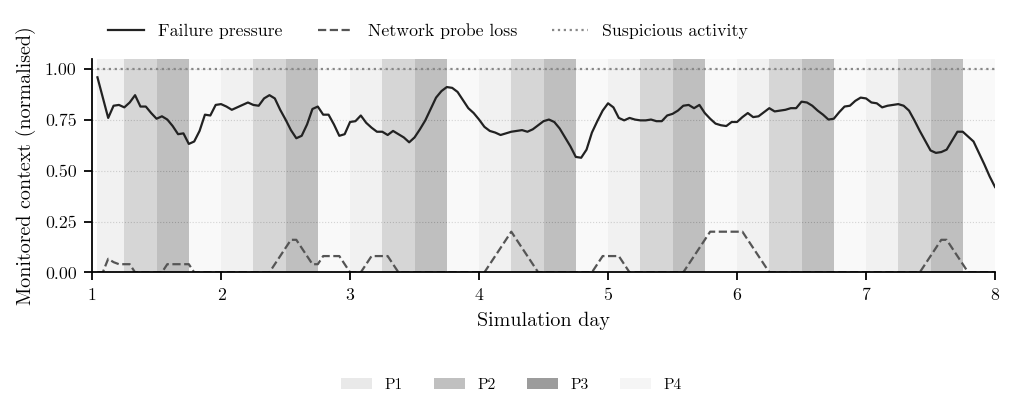

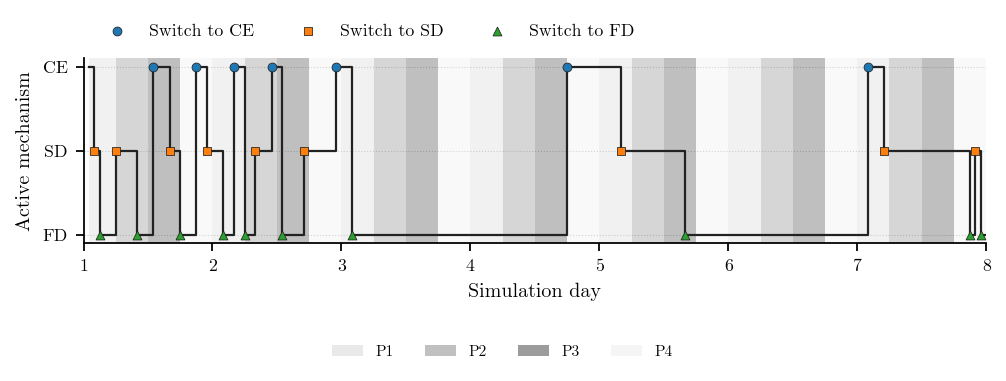

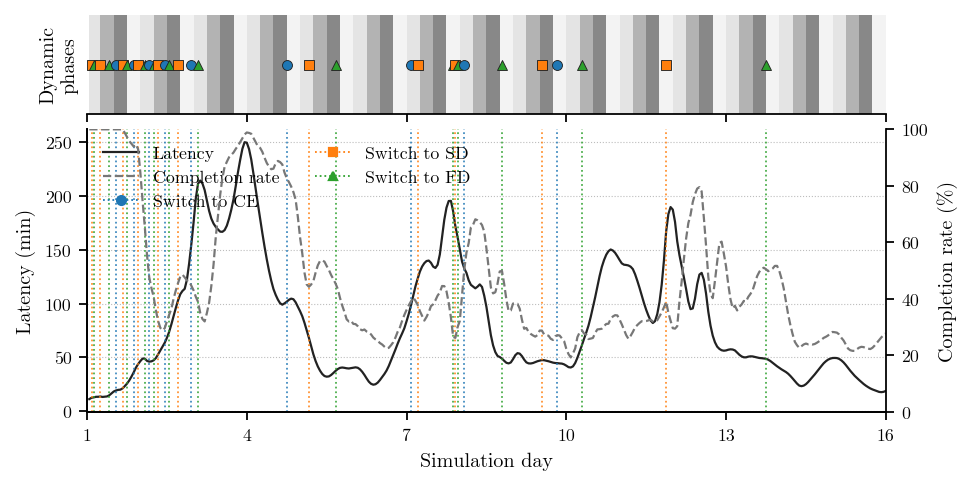

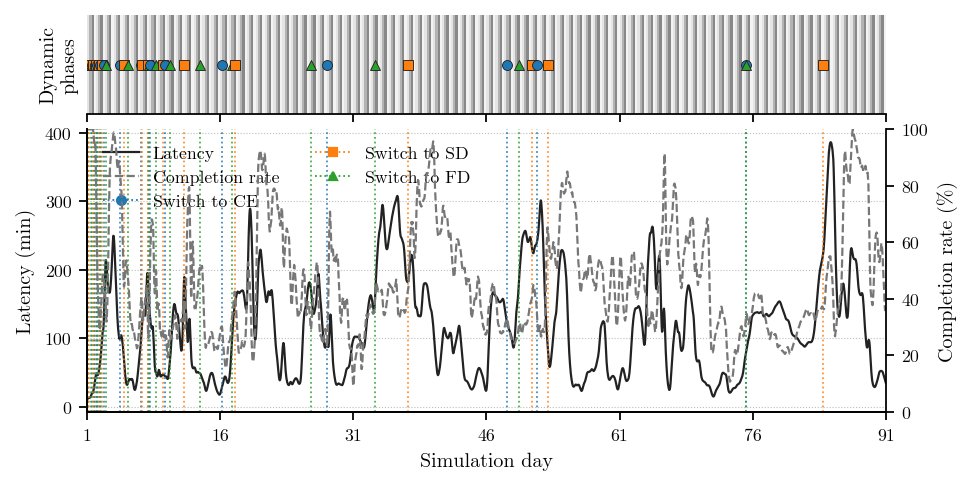

### Completion 100% / latency 0%

### Completion 0% / latency 100%

In [3]:
from pathlib import Path
from subprocess import run
from sys import executable
from IPython.display import Image, Markdown, display

root = Path.home() / 'Desktop' / 'COORDINATE-2.0'
script = root / 'Paper Results' / 'plot_rq2_objective_weights.py'
data = root / 'Paper Results' / 'RQ2'
figures = root / 'Paper Results' / 'paper_figures_latest' / 'rq2_objective_weights'
result = run([executable, str(script), '--data-dir', str(data), '--output-dir', str(figures)], check=True, capture_output=True, text=True)

for slug, label in (
    ('balanced_50_50', 'Completion 50% / latency 50%'),
    ('completion_100', 'Completion 100% / latency 0%'),
    ('latency_100', 'Completion 0% / latency 100%'),
):
    display(Markdown(f'### {label}'))
    for image in sorted((figures / 'previews').glob(f'rq2_{slug}_*.png')):
        display(Image(filename=str(image)))

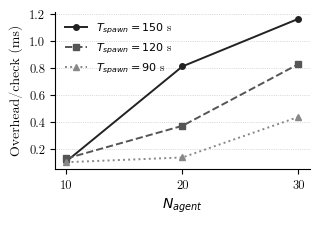

,Mechanism,Simulation wall time (s),Events (avg),Trace size (MB),Adapt. checks (avg),Overhead/check (ms),Overhead share (%)
0,CE,9.61,102732,3.56,-,-,-
3,SD,8.5,99837,3.47,-,-,-
2,FD,6.47,71987,2.6,-,-,-
1,DA,12.32,99869,5.49,4065,0.46,13.87


In [3]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures_latest'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.2)
MULTIPANEL_FIGSIZE = (6.4, 4.2)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'
LINE_COLORS = ['#222222', '#555555', '#888888', '#b3b3b3', '#d0d0d0']
LINE_STYLES = ['-', '--', ':', '-.']
MARKERS = ['o', 's', '^', 'D', 'v']


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def plot_coord_bars(ax, labels, values, width=0.72):
    labels = [str(label) for label in labels]
    x = np.arange(len(labels))
    bars = ax.bar(x, values, width=width)
    apply_hatches(bars, labels)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    style_axes(ax, grid_axis='y')
    return bars


def style_pandas_bar_containers(ax, labels):
    for container, label in zip(ax.containers, labels):
        for patch in container.patches:
            patch.set_facecolor(coord_color(label))
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
            patch.set_hatch(coord_hatch(label))
    style_axes(ax, grid_axis='y')


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)

ROOT = find_results_root(required_all=[Path('RQ3/runs.csv')])
rq3 = ROOT / 'RQ3'
runs_path = rq3 / 'runs.csv'

runs = pd.read_csv(runs_path)
if 'status' in runs.columns:
    runs = runs[runs['status'].fillna('ok') == 'ok'].copy()
else:
    runs = runs.copy()

numeric_cols = [
    'rep', 'item_spawning_time', 'n_robots', 'wall_time_s', 'event_count',
    'events_per_wall_s', 'adapt_checks', 'adapt_overhead_ms_total',
    'adapt_overhead_ms_mean', 'adapt_overhead_ms_p95', 'rtlola_query_ms_mean',
    'scoring_ms_mean', 'adapt_overhead_wall_pct', 'trace_size_mb',
    'overhead_trace_size_mb',
]
for col in numeric_cols:
    if col in runs.columns:
        runs[col] = pd.to_numeric(runs[col], errors='coerce')

runs['coord_label'] = runs['coord_label'].astype(str).str.upper().str.strip()
coord_order = ['CE', 'SD', 'FD', 'DA']
runs = runs[runs['coord_label'].isin(coord_order)].copy()
runs['total_trace_size_mb'] = runs['trace_size_mb'].fillna(0) + runs['overhead_trace_size_mb'].fillna(0)

mechanism_summary = (
    runs.groupby(['coord_label', 'architecture'], as_index=False)
    .agg(
        runs=('run_id', 'count'),
        wall_time_s=('wall_time_s', 'mean'),
        wall_time_s_p95=('wall_time_s', lambda values: values.quantile(0.95)),
        event_count=('event_count', 'mean'),
        total_trace_size_mb=('total_trace_size_mb', 'mean'),
        adapt_checks=('adapt_checks', 'mean'),
        adapt_overhead_ms_mean=('adapt_overhead_ms_mean', 'mean'),
        adapt_overhead_ms_p95=('adapt_overhead_ms_p95', 'mean'),
        rtlola_query_ms_mean=('rtlola_query_ms_mean', 'mean'),
        scoring_ms_mean=('scoring_ms_mean', 'mean'),
        adapt_overhead_wall_pct=('adapt_overhead_wall_pct', 'mean'),
    )
)
mechanism_summary['coord_label'] = pd.Categorical(mechanism_summary['coord_label'], categories=coord_order, ordered=True)
mechanism_summary = mechanism_summary.sort_values('coord_label')

rq3_table = mechanism_summary[[
    'coord_label', 'wall_time_s', 'event_count', 'total_trace_size_mb',
    'adapt_checks', 'adapt_overhead_ms_mean', 'adapt_overhead_wall_pct',
]].rename(columns={
    'coord_label': 'Mechanism',
    'wall_time_s': 'Simulation wall time (s)',
    'event_count': 'Events (avg)',
    'total_trace_size_mb': 'Trace size (MB)',
    'adapt_checks': 'Adapt. checks (avg)',
    'adapt_overhead_ms_mean': 'Overhead/check (ms)',
    'adapt_overhead_wall_pct': 'Overhead share (%)',
})
rq3_table['Simulation wall time (s)'] = rq3_table['Simulation wall time (s)'].round(2)
rq3_table['Events (avg)'] = rq3_table['Events (avg)'].round(0).astype('Int64')
rq3_table['Trace size (MB)'] = rq3_table['Trace size (MB)'].round(2)
rq3_table['Adapt. checks (avg)'] = rq3_table['Adapt. checks (avg)'].round(0).astype('Int64')
rq3_table['Overhead/check (ms)'] = rq3_table['Overhead/check (ms)'].round(2)
rq3_table['Overhead share (%)'] = rq3_table['Overhead share (%)'].round(2)
static_mask = rq3_table['Mechanism'] != 'DA'
rq3_table.loc[static_mask, ['Adapt. checks (avg)', 'Overhead/check (ms)', 'Overhead share (%)']] = pd.NA
rq3_table = rq3_table.astype(object).where(pd.notna(rq3_table), '-')

fig, ax = plt.subplots(1, 1, figsize=(3.3, 2.35))
da = runs[runs['coord_label'] == 'DA'].copy()
if not da.empty:
    overhead = (
        da.groupby(['item_spawning_time', 'n_robots'], as_index=False)
        .agg(overhead_ms=('adapt_overhead_ms_mean', 'mean'))
    )
    spawn_order = [value for value in [150, 120, 90] if value in set(overhead['item_spawning_time'])]
    for idx, spawn in enumerate(spawn_order):
        frame = overhead[overhead['item_spawning_time'] == spawn].sort_values('n_robots')
        ax.plot(
            frame['n_robots'],
            frame['overhead_ms'],
            label=f'$T_{{spawn}}={int(spawn)}$ s',
            color=LINE_COLORS[idx % len(LINE_COLORS)],
            linestyle=LINE_STYLES[idx % len(LINE_STYLES)],
            marker=MARKERS[idx % len(MARKERS)],
            linewidth=1.4,
            markersize=4.0,
        )
    ax.legend(frameon=False, fontsize=8)
else:
    ax.text(0.5, 0.5, 'No DA overhead data', ha='center', va='center')
ax.set_xlabel('$N_{agent}$', fontsize=10)
ax.set_ylabel('Overhead/check (ms)', fontsize=10)
if not da.empty:
    ax.set_xticks(sorted(da['n_robots'].dropna().unique()))
ax.tick_params(axis='both', labelsize=9)
style_axes(ax, grid_axis='y')
fig.tight_layout()
save_or_show(fig, ROOT, 'rq3_runtime_overhead.pdf')
display(rq3_table)

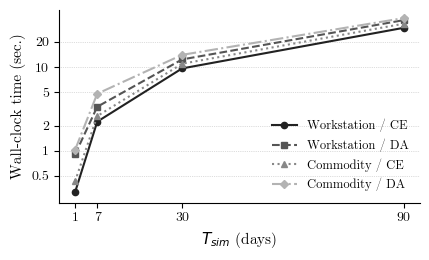

,T_sim (days),Hardware,Mechanism,Peak Memory (MB),Events (avg),Trace size (MB)
0,1,Workstation,CE,35.73,3320,0.11
1,1,Workstation,DA,37.5,3213,0.18
2,1,Commodity,CE,37.86,3320,0.11
3,1,Commodity,DA,39.48,3213,0.18
4,7,Workstation,CE,39.61,23889,0.81
5,7,Workstation,DA,43.0,23234,1.27
6,7,Commodity,CE,41.92,23889,0.81
7,7,Commodity,DA,45.83,23234,1.27
8,30,Workstation,CE,54.64,102741,3.56
9,30,Workstation,DA,63.19,99974,5.5


In [2]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures_latest'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.2)
MULTIPANEL_FIGSIZE = (6.4, 4.2)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'
LINE_COLORS = ['#222222', '#555555', '#888888', '#b3b3b3', '#d0d0d0']
LINE_STYLES = ['-', '--', ':', '-.']
MARKERS = ['o', 's', '^', 'D', 'v']


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def plot_coord_bars(ax, labels, values, width=0.72):
    labels = [str(label) for label in labels]
    x = np.arange(len(labels))
    bars = ax.bar(x, values, width=width)
    apply_hatches(bars, labels)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    style_axes(ax, grid_axis='y')
    return bars


def style_pandas_bar_containers(ax, labels):
    for container, label in zip(ax.containers, labels):
        for patch in container.patches:
            patch.set_facecolor(coord_color(label))
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
            patch.set_hatch(coord_hatch(label))
    style_axes(ax, grid_axis='y')


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)

ROOT = find_results_root(required_all=[Path('RQ4/runs.csv')])
rq4 = ROOT / 'RQ4'
runs_path = rq4 / 'runs.csv'

runs = pd.read_csv(runs_path)
if 'status' in runs.columns:
    runs = runs[runs['status'].fillna('ok') == 'ok'].copy()
else:
    runs = runs.copy()

required_cols = {'coord_label', 'sim_days', 'item_spawning_time', 'n_robots', 'rep'}
missing_cols = sorted(required_cols - set(runs.columns))
if missing_cols:
    raise ValueError(f'RQ4 runs.csv is missing required columns: {missing_cols}')

numeric_cols = [
    'sim_days', 'item_spawning_time', 'n_robots', 'rep', 'wall_time_s', 'event_count',
    'events_per_wall_s', 'max_rss_mb', 'trace_size_mb', 'overhead_trace_size_mb',
    'total_output_size_mb',
]
for col in numeric_cols:
    if col in runs.columns:
        runs[col] = pd.to_numeric(runs[col], errors='coerce')

runs['coord_label'] = runs['coord_label'].astype(str).str.upper().str.strip()
runs = runs[runs['coord_label'].isin(['CE', 'DA'])].copy()
if 'machine_label' in runs.columns:
    raw_machine = runs['machine_label']
else:
    raw_machine = pd.Series('', index=runs.index)
runs['machine_label'] = raw_machine.fillna('').astype(str).str.lower().str.strip()


def hardware_profile(label):
    if label in {'', 'nan', 'none', 'null', 'workstation', 'ws'}:
        return 'Workstation HW'
    if label in {'mac', 'commodity', 'commodity-hardware', 'commodity_hw'}:
        return 'Commodity HW'
    return label.replace('_', ' ').replace('-', ' ').title()

runs['hardware'] = runs['machine_label'].map(hardware_profile)
runs['profile'] = runs['hardware'] + ' / ' + runs['coord_label']
hardware_order = ['Workstation HW', 'Commodity HW']
coord_order = ['CE', 'DA']
profile_order = [f'{hardware} / {coord}' for hardware, coord in product(hardware_order, coord_order)]
profile_labels = {
    'Workstation HW / CE': 'Workstation / CE',
    'Workstation HW / DA': 'Workstation / DA',
    'Commodity HW / CE': 'Commodity / CE',
    'Commodity HW / DA': 'Commodity / DA',
}

summary = (
    runs.groupby(['sim_days', 'hardware', 'coord_label', 'profile'], as_index=False)
    .agg(
        wall_time_s=('wall_time_s', 'mean'),
        event_count=('event_count', 'mean'),
        max_rss_mb=('max_rss_mb', 'mean'),
        total_output_size_mb=('total_output_size_mb', 'mean'),
        runs=('run_id', 'count'),
    )
)
summary['hardware'] = pd.Categorical(summary['hardware'], categories=hardware_order, ordered=True)
summary['coord_label'] = pd.Categorical(summary['coord_label'], categories=coord_order, ordered=True)
summary['profile'] = pd.Categorical(summary['profile'], categories=profile_order, ordered=True)
summary = summary.sort_values(['sim_days', 'hardware', 'coord_label'])

sim_days_order = sorted(summary['sim_days'].dropna().unique())
resource_index = pd.MultiIndex.from_product(
    [sim_days_order, hardware_order, coord_order],
    names=['sim_days', 'hardware', 'coord_label'],
)
resource_source = (
    summary.set_index(['sim_days', 'hardware', 'coord_label'])
    .reindex(resource_index)
    .reset_index()
)
resource_table = resource_source[[
    'sim_days', 'hardware', 'coord_label',
    'max_rss_mb', 'event_count', 'total_output_size_mb',
]].rename(columns={
    'sim_days': 'T_sim (days)',
    'hardware': 'Hardware',
    'coord_label': 'Mechanism',
    'max_rss_mb': 'Peak Memory (MB)',
    'event_count': 'Events (avg)',
    'total_output_size_mb': 'Trace size (MB)',
})
resource_table['Hardware'] = resource_table['Hardware'].str.replace(' HW', '', regex=False)
resource_table['Peak Memory (MB)'] = resource_table['Peak Memory (MB)'].round(2)
resource_table['Events (avg)'] = resource_table['Events (avg)'].round(0).astype('Int64')
resource_table['Trace size (MB)'] = resource_table['Trace size (MB)'].round(2)

series = {profile: summary[summary['profile'] == profile].set_index('sim_days') for profile in profile_order}
profile_line_styles = {
    'Workstation HW / CE': '-',
    'Workstation HW / DA': '-',
    'Commodity HW / CE': '--',
    'Commodity HW / DA': ':',
}
fig, ax = plt.subplots(1, 1, figsize=(4.4, 2.7))
for idx, profile in enumerate(profile_order):
    frame = series.get(profile)
    if frame is None or frame.empty:
        continue
    values = frame['wall_time_s'].reindex(sim_days_order)
    ax.plot(
        sim_days_order,
        values,
        label=profile_labels.get(profile, profile),
        color=LINE_COLORS[idx % len(LINE_COLORS)],
        linestyle=profile_line_styles.get(profile, LINE_STYLES[idx % len(LINE_STYLES)]),
        marker=MARKERS[idx % len(MARKERS)],
        linewidth=1.5,
        markersize=4.5,
    )
ax.set_xlabel('$T_{sim}$ (days)', fontsize=11)
ax.set_ylabel('Wall-clock time (sec.)', fontsize=11)
ax.set_yscale('log')
wall_values = summary['wall_time_s'].dropna()
if not wall_values.empty:
    y_min = max(0.1, wall_values.min() * 0.75)
    y_max = wall_values.max() * 1.25
    tick_candidates = np.array([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000])
    y_ticks = tick_candidates[(tick_candidates >= y_min) & (tick_candidates <= y_max)]
    ax.set_ylim(y_min, y_max)
    ax.set_yticks(y_ticks)
    ax.set_yticklabels([f'{tick:g}' for tick in y_ticks])
    ax.minorticks_off()
ax.set_xticks(sim_days_order)
ax.tick_params(axis='both', labelsize=10)
style_axes(ax, grid_axis='y')
ax.legend(loc='lower right', frameon=False, fontsize=9)
fig.tight_layout()
save_or_show(fig, ROOT, 'rq4_wall_time_scalability.pdf')
resource_table_display = resource_table.astype(object).where(resource_table.notna(), '--')
display(resource_table_display)